In [1]:
!git clone https://github.com/stuniy/SPO_PGU.git

Cloning into 'SPO_PGU'...
remote: Enumerating objects: 98, done.
remote: Counting objects: 100% (29/29), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 98 (delta 8), reused 0 (delta 0), pack-reused 69
Unpacking objects: 100% (98/98), done.


# Поиск гиперпараметров
Итак, если наилучшие параметры найдены путем обучения модели, то как найти наилучшие гиперпараметры? Неужели специалисты по обработке данных просто случайным образом устанавливают их и надеются на лучшее? Что они делают, так это создают множество различных моделей, каждая из которых имеет уникальный набор гиперпараметров. Модель, которая показывает наилучшие результаты в тестовом наборе, будет считаться имеющей наилучшие гиперпараметры. Это делается с помощью перекрестной проверки. Пример, проиллюстрированный ниже, - это когда создаются древовидные модели с одним гиперпараметром, и тестируются четыре разных значения для этого гиперпараметра. Каждое цветовое дерево представляет собой другую древовидную модель (даже если они имеют одинаковую форму — думайте об этом как о значке древовидной модели).

![img](https://drive.google.com/uc?id=1IeVPIgaKkUsgyXsuhjnYc4hCdcGW8qPo)

Теперь, какие значения гиперпараметров обычно проверяются? Другими словами, каковы значения a, b, c и d на изображении выше? Обычно эти значения попадают в диапазон, установленный специалистом по обработке данных. Это связано с тем, что мы хотим избежать переобучения и найти подходящее место (а также сократить время выполнения). Если мы решили, что диапазон гиперпараметра в приведенном выше примере составляет от 1 до 10, то вместо тестирования 1, 1.01, 1.02 вплоть до 10 мы используем 1, 5 и 10.

У моделей, которые мы обучаем, есть набор гиперпараметров, которые мы должны задавать сами, и не можем получить их из данных. Например число кластеров для метода К-средних, вид функции ядра для машин опорных векторов и подобные. 

Но как узнать, какие гиперпараметры лучше брать?

Увы, на такой вопрос нет ответа, в большинстве случаев нельзя заранее знать какой гиперпараметр будет лучше, более того, мы даже не можем сказать какая модель лучше. Нам остается только два варианта: 
- выбирать их интуитивно исходя из нашего опыта, изучения литературы или похожих задач
- перебирать всевозможные значения гиперпараметров и искать наилучшие.

В первом варианте компьютер нам не поможет, а во втором может помочь - пусть компьютер сам перебирает варианты и ищет подходящие нам!

## Поиск по сетке (GridSearchCV) и Случайный поиск (Random Search)
В большинстве случаев у нас есть более одного гиперпараметра. Поскольку мы уже визуализировали один гиперпараметр, давайте визуализируем два. Для этого мы построим два гиперпараметра на осях x и y. В этой плоскости диапазон каждой оси - это диапазон гиперпараметров, которые мы хотим рассмотреть. Теперь, очевидно, из-за вычислительной мощности мы не можем учитывать все значения между максимальными и минимальными, так как же нам выбрать значения для тестирования? Для этого существует два разных метода: поиск по сетке и случайный поиск.

**Поиск по сетке** - это когда вы выбираете x значений, равномерно распределенных вдоль каждой оси (аналогично нашему вводному примеру). Это образует сетку — отсюда и название. 

**Случайный поиск** - это когда число значений в квадрате x выбирается случайным образом. В обоих случаях генерируется число точек в квадрате x. Это можно визуализировать ниже (x=3):

![img](https://drive.google.com/uc?id=1qYACIQucgHBQATRwIfG7RqV7sVGthsYE)

Это здорово и все такое, но какой метод лучше? Что ж, мы лучше определили, насколько хорошо модель с комбинацией гиперпараметров работает на тестовом наборе. Мы можем использовать эти визуализации, чтобы увидеть это. Представьте, что цвет фона указывает на то, насколько точна эта комбинация. Допустим, белый цвет означает, что эта определенная точка работает хорошо, а синий - нет.

![img](https://drive.google.com/uc?id=12mrFTS520IpLb_VD6toX_FgbmEiV0qyZ)

Здесь мы видим, что случайный поиск работает лучше из-за способа выбора значений. В этом примере поиск по сетке проверил только три уникальных значения для каждого гиперпараметра, в то время как случайный поиск проверил 9 уникальных значений для каждого. Это означает, что если один гиперпараметр важнее других, случайный поиск будет лучше. Подумайте об этом так: если гиперпараметр 2 на самом деле не имеет значения, то мы хотели бы проверить 9 различных значений гиперпараметра 1 вместо 3. То же самое справедливо и для более высоких измерений (больше гиперпараметров).

Для этого в модуле [`model_selection`](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.model_selection)библиотеки `sklearn` реализованы функции 
- [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html#sklearn.model_selection.GridSearchCV), поиск по сетке, которая пребирает все комбинации гиперпараметров из заданных значений и сравнивает модели по заданной метрике, 
- [`RandomizedSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html#sklearn.model_selection.RandomizedSearchCV), случайный поиск, которая случайно выбирает комбинации гиперпараметров и сравнивает модели по заданной метрике.

Синтаксис их похож, мы должны указать аргументы:
* `estimator` - модель для которой будем искать гиперпараметры
* `scoring` - название метрики для сравнения (если `None` то будет использован метод `score()` модели)
* `param_grid` для `GridSearchCV` или `param_distributions` для `RandomizedSearchCV` - словарь из названий гиперпараметров и их проверяемых значений или вида распределения для `RandomizedSearchCV`
* `n_iter` для `RandomizedSearchCV` - число проверяемых комбинаций гиперпараметров (у `GridSearchCV` проверяются все комбинации)
* и др.

После обучения эти объекты имеют атрибуты:
* `cv_results_` - словарь, с названиями и значениями результатов, включая статистику по величине `score` и времени выполнения.
* `best_estimator_` - лучшая модель с найденными гиперпараметрами 
* `best_score_` - средне значение `score` для лучшей модели
* `best_params_` - гиперпараметры лучшей модели
* и другие

Методы такие же как и у моделей, из них работают только те, которые у модели есть. Модель обязана иметь методы `fit` и `score`, остальные (`predict`, `predict_proba`, `decision_function`, `transform`, `inverse_transform`)  используются если есть .

Давайте посмотрим на пример и сравним эти две функции. Набритесь терпения, перебор долгий процесс.

In [ ]:
import numpy as np #
from time import time # для замеров времени
import scipy.stats as stats # для задания равномерного распределения
from sklearn.utils.fixes import loguniform # для задания лог-равномерного распределения

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV # методы поиска гиперпараметров
from sklearn.datasets import load_digits # набор данных
from sklearn.linear_model import SGDClassifier # линейный классификатор

# загружаем данные
X, y = load_digits(return_X_y=True)

# создаем модель классификатора
clf = SGDClassifier(loss='hinge', penalty='elasticnet',
                    fit_intercept=True)


# функция для отображения результатов
def report(results, n_top=3): # принимает результаты cv_results_ и число рангов модели
    for i in range(1, n_top + 1): # ранг модели с 1 до n_top + 1 (1 ранг - лучшая модель)
        candidates = np.flatnonzero(results['rank_test_score'] == i) # выбираем результаты для модели текущего ранга
        for candidate in candidates: # перебираем все результаты для нее и выводим на экран 
            print("Model with rank: {0}".format(i)) # ранг
            print("Mean validation score: {0:.3f} (std: {1:.3f})"
                  .format(results['mean_test_score'][candidate], # среднее значение результата на тесте
                          results['std_test_score'][candidate])) # дисперсия результатов на тесте
            print("Parameters: {0}".format(results['params'][candidate])) # значения параметров для этой модели
            print("")

# СЛУЧАЙНЫЙ ПОИСК
# задаем гиперпараметры и их значения или распределения (см. описание гиперпараметров для этой модели)
param_dist = {'average': [True, False], # усреднять \ не усреднять
              'l1_ratio': stats.uniform(0, 1), # коэффициент члена нормализации берется из равномерного распределения от 0 до 1
              'alpha': loguniform(1e-4, 1e0)} # коэффициент альфа берется из лог-равномерного распределения от 0.0001 до 1 

# 
n_iter_search = 20 # число комбинаций гиперпараметров
random_search = RandomizedSearchCV(clf, param_distributions=param_dist, #
                                   n_iter=n_iter_search) # создаем поиск

start = time() # запускаем таймер
random_search.fit(X, y) # обучаем модель с поиском гиперпараметров
print("RandomizedSearchCV took %.2f seconds for %d candidates"
      " parameter settings." % ((time() - start), n_iter_search)) # выводим время обучения и число итераций 
report(random_search.cv_results_) # выводим результаты

# ПОИСК ПО СЕТКЕ
# задаем (те же) гиперпараметры и их конкретные значения (см. описание гиперпараметров для этой модели)
param_grid = {'average': [True, False], #
              'l1_ratio': np.linspace(0, 1, num=10), # от 0 до 1 10 шутк
              'alpha': np.power(10, np.arange(-4, 1, dtype=float))} # от 0.0001 до 1 степень 10ки


grid_search = GridSearchCV(clf, param_grid=param_grid) #  создаем поиск
start = time() # запускаем таймер
grid_search.fit(X, y) # обучаем модель с поиском гиперпараметров

print("GridSearchCV took %.2f seconds for %d candidate parameter settings."
      % (time() - start, len(grid_search.cv_results_['params']))) # выводим время обучения и число итераций #
report(grid_search.cv_results_) # выводим результаты

RandomizedSearchCV took 39.21 seconds for 20 candidates parameter settings.
Model with rank: 1
Mean validation score: 0.929 (std: 0.028)
Parameters: {'alpha': 0.0001380195253867679, 'average': True, 'l1_ratio': 0.009692538607664947}

Model with rank: 2
Mean validation score: 0.925 (std: 0.033)
Parameters: {'alpha': 0.001430272803628316, 'average': True, 'l1_ratio': 0.5838143874534132}

Model with rank: 3
Mean validation score: 0.925 (std: 0.026)
Parameters: {'alpha': 0.00013412010473098565, 'average': True, 'l1_ratio': 0.6359054383559481}



/usr/local/lib/python3.7/dist-packages/sklearn/linear_model/_stochastic_gradient.py:700: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  ConvergenceWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/linear_model/_stochastic_gradient.py:700: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  ConvergenceWarning,
/usr/local/lib/python3.7/dist-packages/sklearn/linear_model/_stochastic_gradient.py:700: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  ConvergenceWarning,


GridSearchCV took 140.57 seconds for 100 candidate parameter settings.
Model with rank: 1
Mean validation score: 0.928 (std: 0.029)
Parameters: {'alpha': 1.0, 'average': False, 'l1_ratio': 0.0}

Model with rank: 2
Mean validation score: 0.927 (std: 0.031)
Parameters: {'alpha': 0.0001, 'average': True, 'l1_ratio': 0.4444444444444444}

Model with rank: 3
Mean validation score: 0.926 (std: 0.030)
Parameters: {'alpha': 0.001, 'average': True, 'l1_ratio': 0.0}



Еще один пример

In [6]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint as sp_randint
from time import time
import pandas as pd
import numpy as np
import seaborn as sns
import scipy.stats as sts
from sklearn.feature_selection import SelectKBest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split


data=pd.read_csv('/content/SPO_PGU/diabetes.csv')
x=data.iloc[:,0:7]
y=data.iloc[:,8]
# обучающая и тестовая выборки по полным данным
# деление на обучающую и тестовую выборки: 80 % - 20 %
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.4, random_state=29)

hp = {"max_depth": [4, 3, 2],
              "min_samples_split": sp_randint(2, 11),
              "criterion": ["gini", "entropy"],
              "bootstrap": [True, False]
              }

# Number of trees used in the boosting process
n_estimators = [100, 500, 900, 1100, 1500]

# Maximum depth of each tree
max_depth = [2, 3, 5, 10, 15]

# Minimum number of samples per leaf
min_samples_leaf = [1, 2, 4, 6, 8]

# Minimum number of samples to split a node
min_samples_split = [2, 4, 6, 10]

# Maximum number of features to consider for making splits
max_features = ['auto', 'sqrt', 'log2', None]

criterion= ["gini", "entropy"]

# Define the grid of hyperparameters to search
hyperparameter_grid = {'n_estimators': n_estimators,
                       'max_depth': max_depth,
                       'criterion':criterion,
                       'min_samples_leaf': min_samples_leaf,
                       'min_samples_split': min_samples_split,
                       'max_features': max_features}

# Create the model to use for hyperparameter tuning
model = RandomForestClassifier(n_estimators=20)

n_iter_search = 10
#random_search = RandomizedSearchCV(model, param_distributions=hp, n_iter=n_iter_search, cv=5)

# Set up the random search with 4-fold cross validation
random_search = RandomizedSearchCV(estimator=model,
                               param_distributions=hyperparameter_grid,
                               cv=4, n_iter=10,
                               scoring = 'neg_mean_absolute_error',
                               n_jobs = -1, verbose = 1,
                               return_train_score = True,
                               random_state=42)


# Fit on the training data
start = time()
best=random_search.fit(x_train, y_train)
print(random_search.best_estimator_)
best_pred = best.predict(x_test)

# check accuracy:
# доля правильных ответов алгоритма: Точность = (истинное положительное + истинно отрицательное значение) / всего
acc = accuracy_score(y_test, best_pred)
print(f"The accuracy score for method is: {round(acc,3)*100}%")


# Create the model to use for hyperparameter tuning
model_best = RandomForestClassifier(random_search.best_estimator_)

print("RandomizedSearchCV took %.2f seconds for %d candidates"
      " parameter settings." % ((time() - start), n_iter_search))
means = random_search.cv_results_['mean_test_score']
stds = random_search.cv_results_['std_test_score']
for mean, std, params in zip(means, stds, random_search.cv_results_['params']):
  print("%0.3f (+/-%0.03f) for %r" % (mean, std * 2, params))

print("The best parameter for RandomForest") 
print(random_search.best_params_)

Fitting 4 folds for each of 10 candidates, totalling 40 fits
RandomForestClassifier(criterion='entropy', max_depth=5, max_features=None,
                       min_samples_leaf=6, min_samples_split=6,
                       n_estimators=1500)
The accuracy score for method is: 74.0%
RandomizedSearchCV took 57.76 seconds for 10 candidates parameter settings.
-0.235 (+/-0.061) for {'n_estimators': 1500, 'min_samples_split': 6, 'min_samples_leaf': 6, 'max_features': None, 'max_depth': 5, 'criterion': 'entropy'}
-0.261 (+/-0.066) for {'n_estimators': 900, 'min_samples_split': 4, 'min_samples_leaf': 1, 'max_features': None, 'max_depth': 10, 'criterion': 'entropy'}
-0.246 (+/-0.048) for {'n_estimators': 100, 'min_samples_split': 2, 'min_samples_leaf': 6, 'max_features': 'auto', 'max_depth': 5, 'criterion': 'gini'}
-0.243 (+/-0.052) for {'n_estimators': 1500, 'min_samples_split': 6, 'min_samples_leaf': 8, 'max_features': 'auto', 'max_depth': 10, 'criterion': 'gini'}
-0.254 (+/-0.076) for {'n_e

Придумайте и назовите два недостатка каждого из подходов - поиска по сетке и случайного поиска.

# Сравнение классификаторов

Мы познакомились с малой частью моделей машинного обучения.

Машинное обучение это не только наука, но и искусство, многое решает ваша интуиция, но так же много зависит и от математической и инженерной подготовки. Это постоянные исследования, сравнения, выбор и модификация решений, причем совершенно в разных плоскостях. Можно бесконечно усложнять и искать подходящие гиперпараметры модели, но она никак не заработает, а можно сменить набор собираемых данных и получить решение простой моделью, или наоборот, для данных которые на первый взгляд кажутся простыми, придется построить сложную модель.

Качество работы модели это совокупная оценка, а не одна величина, мы уже познакомились с некоторыми метриками качества, но следует отметить и другие:

  * время выполнения и обучения модели - очень важный критерий, часто решающий, и выгодней сделать более простую, но менее точную модель, зато решать будет быстрее.
  * возможность применения параллельных вычислителей. Сегодня компьютеры состоят из множества одновременно работающих процессоров (или ядер процессоров), и важно, чтобы алгоритмы модели могли задействовать все эти устройства, чтобы не было простоя. Не для всех алгоритмов такое возможно.

Разработка моделей это постоянные исследования и сравнения, давайте сравним несколько классификаторов между собой. Создадим данные, проведем предобработку, обучим модели и отобразим результаты. Мы используем какие в голову придут классификаторы из тех, что есть в библиотеке sklearn, добавьте\замените их своими, попробуйте разные гиперпараметры.


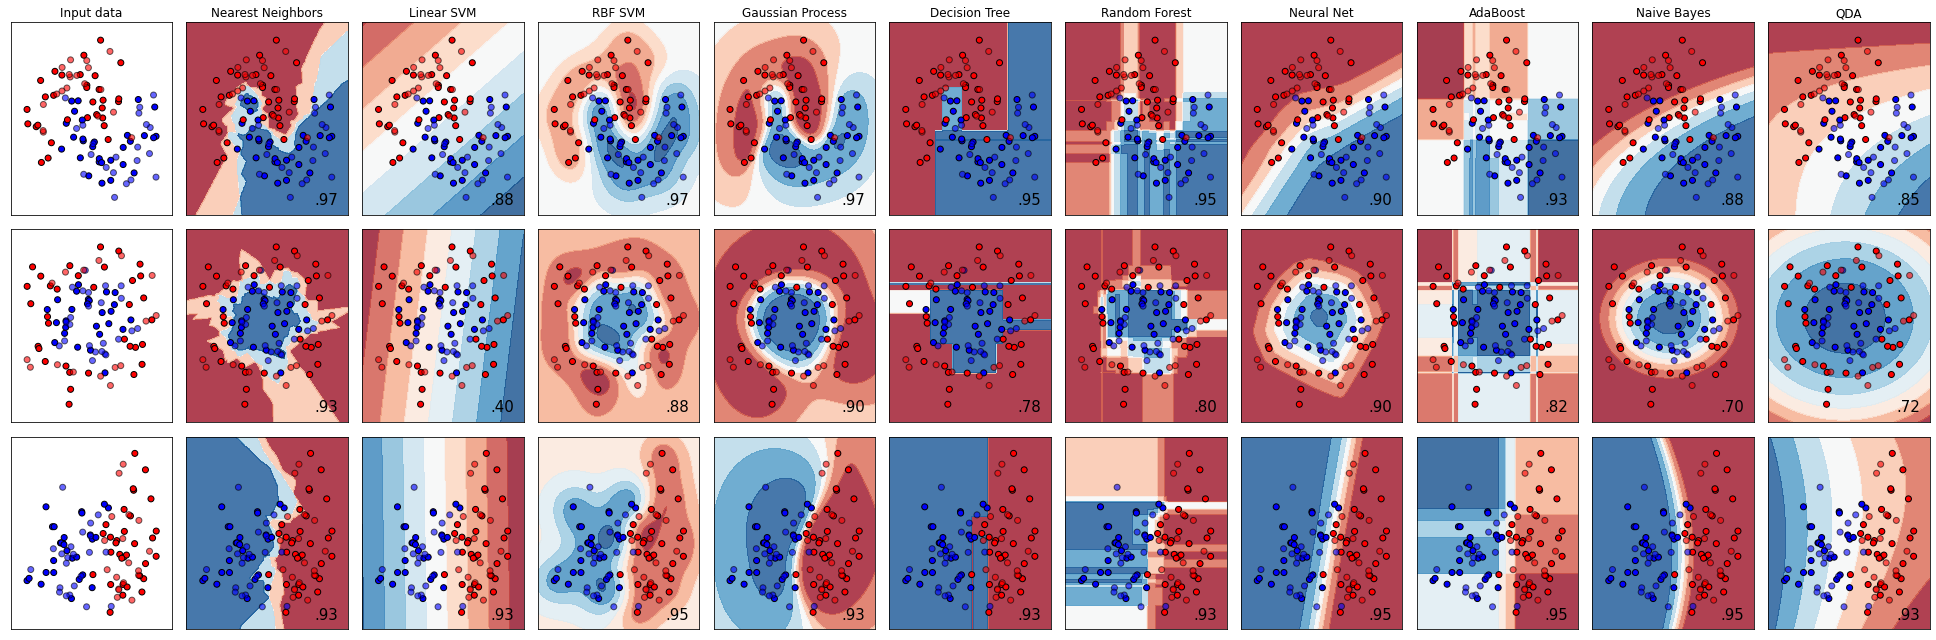

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap # цвета для графиков
from sklearn.model_selection import train_test_split # разделение на обучение и тест
from sklearn.preprocessing import StandardScaler # для масштабирования
from sklearn.datasets import make_moons, make_circles, make_classification # некоторые генераторы наглядных данных
from sklearn.neural_network import MLPClassifier # нейронная сеть (еще не проходили, но использовать лекго)
from sklearn.neighbors import KNeighborsClassifier # ближайшие соседи
from sklearn.svm import SVC # машина опорных векторов
from sklearn.gaussian_process import GaussianProcessClassifier # еще какая-то модель 
from sklearn.gaussian_process.kernels import RBF # и еще
from sklearn.tree import DecisionTreeClassifier # дерево
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier # случайный лес и бустинг
from sklearn.naive_bayes import GaussianNB # наивный Байес
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis # еще одна не известная нам модель... их много
# добавьте свои модели

h = .02  # шаг для сетки проверки и рисования
# названия моделей
names = [
    "Nearest Neighbors", "Linear SVM", "RBF SVM", "Gaussian Process",
    "Decision Tree", "Random Forest", "Neural Net", "AdaBoost", "Naive Bayes",
    "QDA"
]

# инициализируем классификаторы
classifiers = [
    KNeighborsClassifier(3),
    SVC(kernel="linear", C=0.025),
    SVC(gamma=2, C=1),
    GaussianProcessClassifier(1.0 * RBF(1.0)),
    DecisionTreeClassifier(max_depth=5),
    RandomForestClassifier(max_depth=5, n_estimators=10, max_features=1),
    MLPClassifier(alpha=1, max_iter=1000),
    AdaBoostClassifier(),
    GaussianNB(),
    QuadraticDiscriminantAnalysis()]

# генерируем данные - три набора точек двух классов на плоскости
# третий набор - два кластера
X, y = make_classification(n_features=2, n_redundant=0, n_informative=2,
                           random_state=1, n_clusters_per_class=1)

rng = np.random.RandomState(2) #

X += 2 * rng.uniform(size=X.shape) # шум

linearly_separable = (X, y) #
# три набора
datasets = [make_moons(noise=0.3, random_state=0), # первый - две пересекающиеся полуокружности 
            make_circles(noise=0.2, factor=0.5, random_state=1),# второй - две вложенные окружности
            linearly_separable # третий - два овальных кластера
            ]

# обучаем классификаторы на данных и отображаем результаты.

figure = plt.figure(figsize=(27, 9)) # 
i = 1 # номер подграфика
# цикл по количеству наборов данных
for ds_cnt, ds in enumerate(datasets):
    # предобработка
    X, y = ds # разделяем входы и указания учителя
    X = StandardScaler().fit_transform(X) # масштабируем входы
    # разделяем на обучение и тест
    X_train, X_test, y_train, y_test = \
        train_test_split(X, y, test_size=.4, random_state=42) #
    # сетка для теста, чуть больше чем минимальные\максимальные значения входов
    x_min, x_max = X[:, 0].min() - .5, X[:, 0].max() + .5 # по одной оси
    y_min, y_max = X[:, 1].min() - .5, X[:, 1].max() + .5 # по другой оси
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), # создаем сетку
                         np.arange(y_min, y_max, h)) #

    # рисуем наборы данных
    cm = plt.cm.RdBu # цветовая схема
    cm_bright = ListedColormap(['#FF0000', '#0000FF']) # вот эти цвета возьмем
    ax = plt.subplot(len(datasets), len(classifiers) + 1, i) # подграфик для рисования
    if ds_cnt == 0: # для первого
        ax.set_title("Input data") # подписываем заголовок 
    # рисуем обучающие точки
    ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright,
               edgecolors='k')
    # рисуем тестовые точки с прозрачностью
    ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright, alpha=0.6,
               edgecolors='k')
    ax.set_xlim(xx.min(), xx.max()) # область отображения по х
    ax.set_ylim(yy.min(), yy.max()) # область отображения по у 
    ax.set_xticks(()) # убираем деления осей по х
    ax.set_yticks(()) # убираем деления осей по у
    i += 1 # номер следующего подграфика

    # цикл по классификаторам
    for name, clf in zip(names, classifiers): #
        ax = plt.subplot(len(datasets), len(classifiers) + 1, i) # текущий подграфик
        clf.fit(X_train, y_train) # обучаем классификатор
        score = clf.score(X_test, y_test) # считаем его score на тесте

        # считаем разделяющую поверхность
        if hasattr(clf, "decision_function"): # если у классификатора есть метод decision_function
            # то его и используем
            Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]) #
        else: # а если нет
            # то считаем через predict_proba()
            Z = clf.predict_proba(np.c_[xx.ravel(), yy.ravel()])[:, 1] #

        # рисуем разделяющую поверхность
        Z = Z.reshape(xx.shape) # собираем обратно в матрицу
        ax.contourf(xx, yy, Z, cmap=cm, alpha=.8) # рисуем, полупрозрачно

        # рисуем обучающие точки 
        ax.scatter(X_train[:, 0], X_train[:, 1], c=y_train, cmap=cm_bright,
                   edgecolors='k')
        #  рисуем тестовые точки 
        ax.scatter(X_test[:, 0], X_test[:, 1], c=y_test, cmap=cm_bright,
                   edgecolors='k', alpha=0.6)

        ax.set_xlim(xx.min(), xx.max())
        ax.set_ylim(yy.min(), yy.max())
        ax.set_xticks(())
        ax.set_yticks(())
        if ds_cnt == 0: # для первой строки подграфиков
            ax.set_title(name) # подписываем заголовок 
        # добавляем на график текст с величиной score 
        ax.text(xx.max() - .3, yy.min() + .3, ('%.2f' % score).lstrip('0'),
                size=15, horizontalalignment='right')
        i += 1 # номер следующего подграфика
        
plt.tight_layout() # более компактное расположение подграфиков
plt.show() # отображаем на экране

Даже на этих простых данных, как мы видим, нельзя сказать что одна модель всегда лучше другой: для одних данных лучше одни модели, для других - другие. 

## Выводы
Параметры обнаруживаются, когда определенный тип модели обучается на наборе данных.

Гиперпараметры - это аспекты модели, которые задаются перед обучением специалистом по обработке данных. Они могут быть оптимизированы с помощью поиска по сетке или случайного поиска.

Поиск по сетке генерирует равномерно распределенные значения для каждого тестируемого гиперпараметра, а затем использует перекрестную проверку для проверки точности каждой комбинации

Случайный поиск генерирует случайные значения для каждого тестируемого гиперпараметра, а затем использует перекрестную проверку для проверки точности каждой комбинации.

Случайный поиск лучше, чем поиск по сетке, потому что он может учитывать больше уникальных значений каждого гиперпараметра. Это важно, потому что некоторые гиперпараметры более важны, чем другие.

## Домашнее задание 
1. Выберете любую модель которую вы изучили
2. Подберите гиперпараметры используя метод поиск по сетке для вашей модели
3. Подберите гиперпараметры используя метод случайный пиоск для вашей модели
4. Сравните какой метод дал лучший результат